# 05 Trends: emerging categories and online-hiring signals

| Field | Value |
|---|---|
| **Purpose** | Which job functions and title words grow or shrink within the data window, and how the geography and structure of online hiring move |
| **Assignment requirement** | **Task 2** (emerging job categories) and **Task 7** (remote-work landscape; the forecasts follow in Notebook 06) |
| **Inputs** | `trend_*.csv` and `remote_*.csv` from the pipeline's `trends` step |
| **Outputs** | None; the tables are reused by Notebook 06 (forecasts) and the dashboard |
| **Build identity** | Printed by the first code cell |

**Read this first: the window is short.** Only the 37 complete days from 16 February to 23 March 2024 are used (Notebook 01). A "trend" here means **change within these five weeks**. It cannot show a long-term trend, and part of it may be seasonal (for example, the start of a quarter or the US tax season). Every result is reported with that limit.

**How a trend is measured (decision D-032)**

- For each job function, the **share of all jobs posted that day**. Shares cancel out the weekly rhythm and the collection gaps that move raw counts.
- A straight line is fitted through the 37 daily shares **with weekday adjustment** (a Saturday is compared with Saturdays). The result is the change from the first to the last day of the window.
- Changes are given in **percentage points** (pp) *and* as a **relative change**: a share moving from 1.00% to 1.13% is +0.13 pp, or +13% relative. The relative number alone can make a small movement look large.
- Neighbouring days are similar, so ordinary standard errors would be too small. The **Newey-West** method corrects for this; its lag (7 days) was fixed before any result was computed.
- 22 functions are tested at once, so p-values are adjusted for false discoveries (**FDR**, as in Notebook 04). With only 37 days, the size of a change and its interval matter more than its p-value.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261004T122311Z-98262faf0c
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 40 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.taxonomy import CATEGORIES, OTHER
from job_market.trends import COUNTRY_REGION, trend_fit

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)

daily = project.read_csv("trend_category_daily.csv", parse_dates=["date"])
categories = project.read_csv("trend_categories.csv")
other = project.read_csv("trend_other_monitor.csv")
keywords = project.read_csv("trend_keywords.csv")
new_terms = project.read_csv("trend_new_terms_weekly.csv")
geo_weekly = project.read_csv("remote_geography_weekly.csv")
regions = project.read_csv("remote_regions_weekly.csv")
remote_daily = project.read_csv("remote_daily.csv", parse_dates=["date"])
signals = project.read_csv("remote_signals_weekly.csv")
series = project.read_csv("remote_series_trends.csv").set_index("series")
rules = project.settings.section("trends")
jobs = project.read_parquet("jobs_clean.parquet", columns=["country", "eligible_for_timeseries"])

NAMES = {key: name for key, (name, _) in CATEGORIES.items()}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
window_jobs = int(daily.groupby("date")["jobs"].sum().sum())
print(f"Window: {daily['date'].min():%d %b} - {daily['date'].max():%d %b %Y}, {daily['date'].nunique()} days, "
      f"{window_jobs:,} jobs; Newey-West lag {rules['newey_west_lag']} days")

Window: 16 Feb - 23 Mar 2024, 37 days, 229,520 jobs; Newey-West lag 7 days


## 1. Task 2: emerging job categories

### 1.1 First, a check on the categories themselves

If the share of jobs the categorizer leaves as *Other / Unclear* drifted during the window, apparent changes in named categories could be an artefact of categorization coverage. So *Other* is not tested as an "emerging category"; it is monitored separately.

In [3]:
other.round(3)

,series,mean_pct,start_pct,end_pct,change_pp,change_low_pp,change_high_pp,p
0,other_unclear share,12.458,12.435,12.482,0.047,-0.345,0.439,0.815


**Finding.** The share of *Other / Unclear* stays essentially flat (about 12.5% throughout; change about +0.05 pp, interval spanning zero). The movements of named categories below are not caused by changing categorization coverage.

### 1.2 Which functions grow and which shrink

In [4]:
table = categories.copy()
table["name"] = table["primary_category"].map(NAMES)
significant_categories = int((table["p_fdr"] < 0.05).sum())
print(f"Functions with a trend significant at FDR 5%: {significant_categories} of {len(table)}")
table[["name", "mean_share_pct", "start_share_pct", "end_share_pct", "change_pp", "change_low_pp", "change_high_pp",
       "relative_change_pct", "p_fdr"]].set_index("name").round(3)

Functions with a trend significant at FDR 5%: 9 of 22


,mean_share_pct,start_share_pct,end_share_pct,change_pp,change_low_pp,change_high_pp,relative_change_pct,p_fdr
name,,,,,,,,
Digital Marketing,10.517,9.998,11.035,1.037,0.445,1.628,10.371,0.002
Web Development,14.528,14.164,14.891,0.727,0.040,1.414,5.131,0.076
Video & Animation,6.800,6.484,7.116,0.632,0.147,1.117,9.745,0.026
Design & Creative,11.638,11.386,11.890,0.503,0.118,0.889,4.422,0.026
Software & IT,7.458,7.275,7.641,0.366,0.040,0.692,5.025,0.062
Sales & Lead Generation,3.906,3.724,4.088,0.363,0.173,0.553,9.753,0.001
AI & Machine Learning,1.408,1.284,1.531,0.247,0.131,0.363,19.212,0.000
"Business, Project Management & Consulting",3.320,3.227,3.413,0.185,-0.081,0.452,5.743,0.253
E-commerce Operations,1.767,1.689,1.845,0.156,0.082,0.231,9.266,0.000


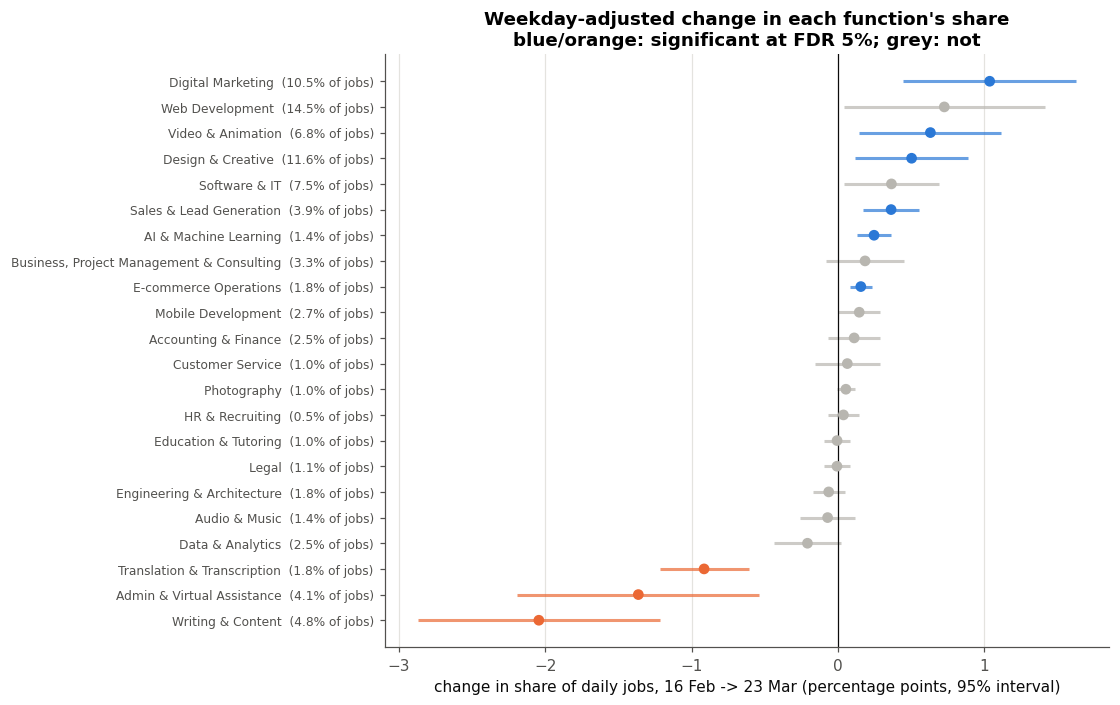

In [5]:
order = table.sort_values("change_pp")
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(order))
colors = [GREY if p >= 0.05 else (BLUE if c > 0 else ORANGE) for p, c in zip(order["p_fdr"], order["change_pp"])]
ax.hlines(y, order["change_low_pp"], order["change_high_pp"], color=colors, lw=2, alpha=0.7)
ax.scatter(order["change_pp"], y, color=colors, zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{n}  ({s:.1f}% of jobs)" for n, s in zip(order["name"], order["mean_share_pct"])], fontsize=8)
ax.set_xlabel("change in share of daily jobs, 16 Feb -> 23 Mar (percentage points, 95% interval)")
ax.set_title("Weekday-adjusted change in each function's share\nblue/orange: significant at FDR 5%; grey: not")
ax.grid(axis="y", visible=False)
plt.show()

**Finding.**

- **Shrinking:** *Writing & Content* falls from about 5.8% to 3.7% of daily jobs (about **-2.0 pp**, -35% relative), *Admin & Virtual Assistance* by about **-1.4 pp** (-29%) and *Translation & Transcription* by about **-0.9 pp** (-41%).
- **Growing:** *Digital Marketing* gains about **+1.0 pp** (+10%), *Video & Animation* +0.6 pp, *Design* +0.5 pp, *Sales & Lead Generation* +0.4 pp. *AI & Machine Learning* is small but grows fastest in relative terms (**+19%**, +0.25 pp); *E-commerce* also grows (+9%).
- Nine of the 22 functions have a trend significant at FDR 5%; the others move too little to separate from day-to-day noise.

The daily shares behind the strongest movements (7-day rolling average over the raw daily shares):

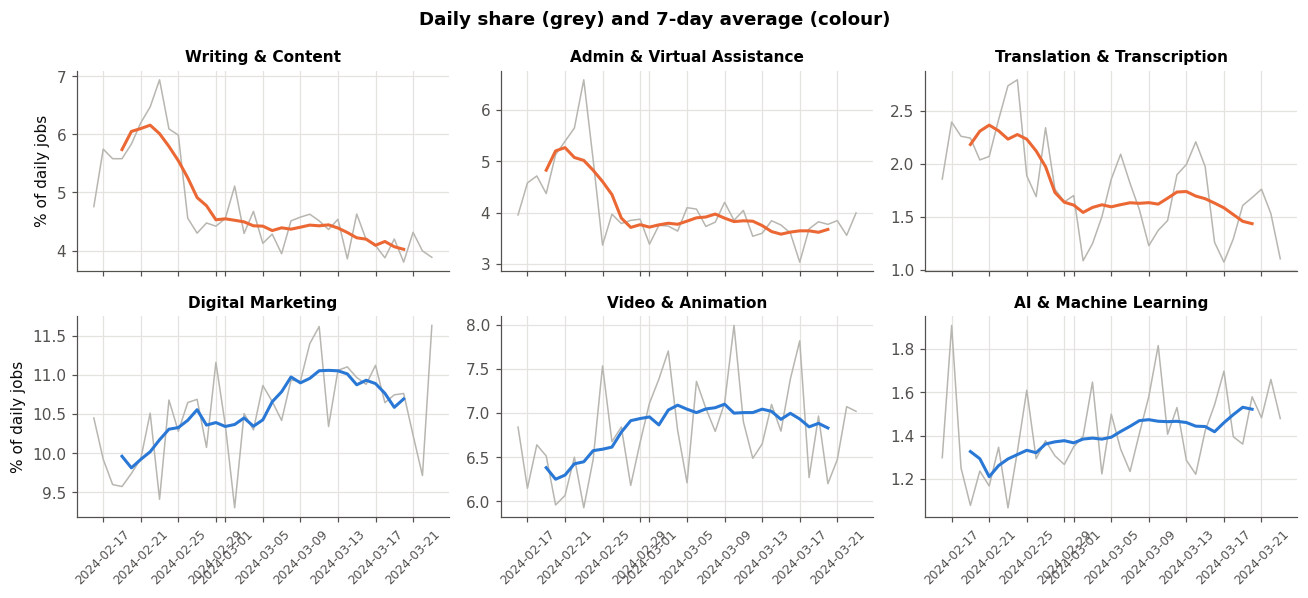

In [6]:
show = ["writing_content", "admin_virtual_assistance", "translation_transcription",
        "digital_marketing", "video_animation", "ai_ml"]
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
for ax, cat in zip(axes.flat, show):
    part = daily[daily["primary_category"] == cat].sort_values("date")
    color = ORANGE if cat in show[:3] else BLUE
    ax.plot(part["date"], 100 * part["share"], color=GREY, lw=1)
    ax.plot(part["date"], 100 * part["share"].rolling(7, center=True).mean(), color=color, lw=2)
    ax.set_title(NAMES[cat], fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0, 0].set_ylabel("% of daily jobs")
axes[1, 0].set_ylabel("% of daily jobs")
fig.suptitle("Daily share (grey) and 7-day average (colour)", fontweight="bold")
fig.tight_layout()
plt.show()

### 1.3 Do these trends survive the checks?

Three checks: the same trend **without possible reposts** (a few clients batch-posting could fake a trend), **without the three intraday-gap days**, and a simple second method: the share in the **first two complete Monday-Sunday weeks** (19 Feb - 3 Mar) against the **last two** (4 - 17 Mar), which have the same weekday mix.

In [7]:
checks = table.set_index("name")[["change_pp", "change_pp_without_possible_reposts", "change_pp_without_gap_days",
                                  "week_change_pp", "relative_change_pct", "week_relative_pct", "p_fdr"]]
checks.columns = ["trend pp", "no reposts pp", "no gap days pp", "week comparison pp", "trend relative %",
                  "week comparison relative %", "p_fdr"]
robust = checks[checks["p_fdr"] < 0.05].copy()
same_sign = (np.sign(robust[["no reposts pp", "no gap days pp", "week comparison pp"]])
             .eq(np.sign(robust["trend pp"]), axis=0).all(axis=1))
print(f"Significant trends whose direction holds in all three checks: {int(same_sign.sum())} of {len(robust)}")
checks.round(2)

Significant trends whose direction holds in all three checks: 9 of 9


,trend pp,no reposts pp,no gap days pp,week comparison pp,trend relative %,week comparison relative %,p_fdr
name,,,,,,,
Digital Marketing,1.04,0.81,0.83,0.67,10.37,6.60,0.00
Web Development,0.73,0.78,0.69,0.28,5.13,1.94,0.08
Video & Animation,0.63,0.35,0.35,0.37,9.74,5.52,0.03
Design & Creative,0.50,0.57,0.46,0.34,4.42,3.01,0.03
Software & IT,0.37,0.36,0.40,0.15,5.02,2.03,0.06
Sales & Lead Generation,0.36,0.36,0.40,0.04,9.75,1.11,0.00
AI & Machine Learning,0.25,0.29,0.30,0.12,19.21,9.31,0.00
"Business, Project Management & Consulting",0.19,0.11,0.14,0.17,5.74,5.15,0.25
E-commerce Operations,0.16,0.13,0.17,0.07,9.27,4.40,0.00


**Finding.** For every significant trend, the direction holds in all three checks. The size depends on the method: the weekday-adjusted line gives larger relative changes than the complete-week comparison (writing: -35% versus -19%), because the line also uses the first days of the window, while the week comparison starts on 19 February.

### 1.4 A gradual trend, or one step?

The daily charts above show something a straight line hides: writing, admin and translation shares are **high in the first ten days and then drop to a lower level around 26 February**, after which they are much flatter. A line fitted through all 37 days turns such a step into a steady decline. So the trend is re-estimated on the later part of the window only (26 February - 23 March, 27 days).

*This split date was chosen after looking at the chart, so this is an exploratory check, not a pre-planned test.*

In [8]:
rows = []
for cat in ["writing_content", "admin_virtual_assistance", "translation_transcription", "digital_marketing",
            "video_animation", "design_creative", "sales_lead_generation", "ecommerce_operations", "ai_ml"]:
    part = daily[daily["primary_category"] == cat].sort_values("date")
    early, late = part[part["date"] < "2024-02-26"], part[part["date"] >= "2024-02-26"]
    fit = trend_fit(late["share"].to_numpy(), late["date"], rules["newey_west_lag"])
    rows.append({"name": NAMES[cat], "share 16-25 Feb (%)": 100 * early["share"].mean(),
                 "share 26 Feb-23 Mar (%)": 100 * late["share"].mean(),
                 "later trend pp": 100 * fit["change"], "later low pp": 100 * fit["change_low"],
                 "later high pp": 100 * fit["change_high"], "later relative %": fit["relative_change_pct"]})
step_check = pd.DataFrame(rows).set_index("name")
step_check["later trend clear"] = np.where((step_check["later low pp"] > 0) | (step_check["later high pp"] < 0), "yes", "no")
step_check.round(2)

,share 16-25 Feb (%),share 26 Feb-23 Mar (%),later trend pp,later low pp,later high pp,later relative %,later trend clear
name,,,,,,,
Writing & Content,5.92,4.32,-0.61,-0.78,-0.43,-13.14,yes
Admin & Virtual Assistance,4.88,3.77,-0.14,-0.35,0.07,-3.62,no
Translation & Transcription,2.27,1.62,-0.19,-0.43,0.04,-11.30,no
Digital Marketing,10.01,10.70,0.44,-0.15,1.03,4.21,no
Video & Animation,6.46,6.93,-0.14,-0.37,0.09,-1.97,no
Design & Creative,11.38,11.73,0.13,-0.14,0.39,1.08,no
Sales & Lead Generation,3.74,3.97,0.35,0.01,0.68,9.18,yes
E-commerce Operations,1.72,1.78,0.13,0.03,0.22,7.39,yes
AI & Machine Learning,1.33,1.44,0.18,0.11,0.25,13.43,yes


**Finding.**

- **Writing** keeps falling inside the later window too (about -13% relative): a real decline, plus an early step.
- **AI & ML** (+13%), **Sales** (+9%) and **E-commerce** (+7%) keep rising in the later window: gradual growth.
- **Admin**, **Translation**, **Marketing**, **Video** and **Design** show no clear trend in the later window: most of their full-window change is the early step.

A step at the start of a dataset can mean a real market change, a batch of postings in the first days, or a change in how the data was collected. This data cannot separate these. So the honest summary is: **within these five weeks, the shares of writing, admin and translation work are lower at the end than at the start, with writing still declining; AI, sales and e-commerce grow steadily; the other changes are mostly an early shift.**

### 1.5 Rising and falling title words

Categories are broad, and Notebook 03 showed that many real jobs sit in *Other*. Title words give a finer view that does not depend on the categorizer. The same support rules as Notebook 04 apply (at least 300 jobs and 100 distinct titles), plus presence in **at least 3 different weeks**, so a one-week burst cannot pose as a five-week trend.

In [9]:
significant_keywords = keywords[keywords["p_fdr"] < 0.05]
print(f"Keywords tested: {len(keywords)}; significant at FDR 5%: {len(significant_keywords)}")
cols = ["keyword", "jobs", "mean_share_pct", "change_pp", "relative_change_pct", "relative_low_pct",
        "relative_high_pct", "week_relative_pct", "p_fdr"]
print("Fastest rising (significant):")
display(significant_keywords.nlargest(15, "relative_change_pct")[cols].round(3))
print("Fastest falling (significant):")
significant_keywords.nsmallest(15, "relative_change_pct")[cols].round(3)

Keywords tested: 726; significant at FDR 5%: 138
Fastest rising (significant):


,keyword,jobs,mean_share_pct,change_pp,relative_change_pct,relative_low_pct,relative_high_pct,week_relative_pct,p_fdr
0,run,327,0.145,0.122,144.127,72.548,215.705,55.752,0.001
1,react js,304,0.133,0.097,114.192,42.934,185.450,57.210,0.013
2,web3,341,0.150,0.103,103.835,39.173,168.497,19.218,0.013
3,crypto,1011,0.448,0.293,97.298,69.971,124.624,41.155,0.000
4,character,373,0.166,0.096,81.978,54.312,109.643,38.606,0.000
6,next,596,0.261,0.143,75.566,45.821,105.310,40.232,0.000
7,30,472,0.209,0.113,74.375,37.182,111.567,12.242,0.001
9,line,302,0.133,0.070,71.683,39.774,103.591,27.273,0.000
12,client,711,0.310,0.156,67.409,56.087,78.730,18.594,0.000
13,play,554,0.246,0.122,65.912,18.428,113.397,40.880,0.038


Fastest falling (significant):


,keyword,jobs,mean_share_pct,change_pp,relative_change_pct,relative_low_pct,relative_high_pct,week_relative_pct,p_fdr
725,freelancers,526,0.232,-0.368,-88.508,-125.845,-51.171,-53.092,0.000
724,general,420,0.183,-0.232,-77.813,-109.380,-46.246,-48.582,0.000
723,writers,619,0.277,-0.321,-73.464,-102.577,-44.351,-31.442,0.000
722,data entry,1730,0.753,-0.815,-70.245,-104.091,-36.399,-39.700,0.001
720,freelancer,852,0.371,-0.336,-62.343,-87.773,-36.913,-37.100,0.000
719,documents,383,0.169,-0.153,-62.263,-85.300,-39.226,-28.994,0.000
718,italian,524,0.226,-0.204,-62.160,-91.981,-32.338,-27.157,0.001
717,words,578,0.253,-0.217,-59.994,-87.495,-32.493,-39.046,0.000
716,copy,1342,0.592,-0.450,-55.054,-94.146,-15.962,-38.921,0.035
715,writing,1452,0.634,-0.474,-54.402,-83.629,-25.175,-37.976,0.003


**Finding.**

- **Falling words confirm the category picture from a second angle:** "freelancers", "writers", "data entry", "translation", "writing", "words", "documents", "copy paste" lose roughly half of their share within the window.
- **Rising words point to specific technologies and markets:** "crypto" (about +97%) and "web3", the web frameworks "react js" and "next js", "google play", "google sheets" and "ads manager". The rise of crypto-related titles coincides with the early-2024 cryptocurrency price rally; this notebook does not test that link.
- Some rising words are generic ("run", "next", "line", "client"); they are listed for completeness but carry no clear meaning on their own.

### 1.6 New or notable terms: too rare to call

Several much-discussed terms appear in titles, but far too rarely for any trend inference. Their weekly counts are shown as description only (week 2024-W07 has 3 days, 2024-W12 has 6):

In [10]:
counts = new_terms.pivot(index="term", columns="iso_week", values="jobs")
counts["total"] = counts.sum(axis=1)
counts.sort_values("total", ascending=False)

iso_week,2024-W07,2024-W08,2024-W09,2024-W10,2024-W11,2024-W12,total
term,,,,,,,
ugc,57,196,166,169,215,170,973
chatgpt,26,57,66,48,56,57,310
faceless,13,63,43,54,38,46,257
gpt,12,47,40,34,37,35,205
llm,12,36,39,25,29,31,172
tiktok shop,9,34,30,32,34,27,166
midjourney,9,15,21,25,22,18,110
vision pro,2,8,4,9,6,7,36
gemini,1,8,3,3,4,4,23


"Sora", "Claude", "Devin" and "AI agent" appear in only a handful of titles per week; "Gemini" in a few. They show that new tools reach job titles quickly, but these counts cannot support a trend claim. Broader terms ("chatgpt", "ugc", "tiktok shop") are frequent enough to be stable from week to week.

### 1.7 What the Task 2 results mean, and what they do not

- **Consistent with** a picture in which text work (writing, translation, data entry) loses share while promotion, video and AI work gain. That matches widely discussed effects of generative AI tools in early 2024, but five weeks of observational data **cannot show a cause**.
- **Not a long-term trend.** Five weeks can include seasonal effects and events.
- **Collection is a black box.** The dataset's collection method is not documented; a change in what the collector captured would look like a trend, and the early step in section 1.4 could be one. The stable *Other* share and the consistent keyword results argue against a categorization artefact, but cannot rule out a collection effect.

## 2. Task 7: the online-hiring landscape

**Upwork is primarily an online freelance marketplace, and this dataset has no structured remote/on-site field. Therefore, it cannot estimate the percentage of jobs that are remote. Task 7 instead examines the geography, engagement structure and explicitly stated work-arrangement signals of online hiring.**

Three signals, each over time: **where the clients are**, **what kind of engagement they offer**, and **what titles explicitly say** about the work arrangement. Short-horizon forecasts of the signals with enough data follow in **Notebook 06**.

### 2.1 Where the clients are

Client countries are grouped into World Bank regions. Missing countries stay missing (about 2% of jobs) and are never given a region.

In [11]:
unmapped = sorted(set(jobs.loc[jobs["eligible_for_timeseries"], "country"].dropna()) - set(COUNTRY_REGION))
print(f"Client countries without a region: {unmapped if unmapped else 'none'}")
region_table = regions.pivot(index="iso_week", columns="region", values="share_pct").round(1)
region_table["days in week"] = geo_weekly.set_index("iso_week")["days"]
region_table

Client countries without a region: none


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,Middle East & North Africa,North America,South Asia,Sub-Saharan Africa,days in week
iso_week,,,,,,,,
2024-W07,10.0,23.1,1.7,5.3,47.2,11.0,1.7,3
2024-W08,11.2,23.4,2.1,4.9,45.0,11.3,2.1,7
2024-W09,11.3,24.4,1.9,4.5,47.2,9.0,1.7,7
2024-W10,11.2,24.2,2.0,5.0,47.0,8.9,1.6,7
2024-W11,11.5,24.6,1.9,4.9,46.2,9.4,1.5,7
2024-W12,11.8,24.3,1.8,4.7,46.7,9.4,1.4,6


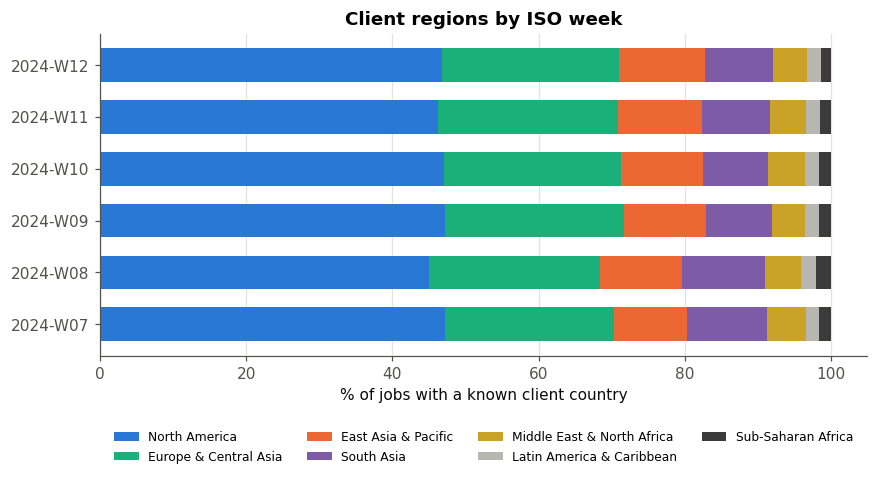

In [12]:
pivot = regions.pivot(index="iso_week", columns="region", values="share_pct")
pivot = pivot[pivot.mean().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(pivot))
palette = [BLUE, AQUA, ORANGE, "#7d5ba6", "#c9a227", GREY, "#3b3b3b"]
for color, region in zip(palette, pivot.columns):
    ax.barh(pivot.index, pivot[region], left=left, color=color, label=region, height=0.65)
    left += pivot[region].to_numpy()
ax.set_xlabel("% of jobs with a known client country")
ax.set_title("Client regions by ISO week")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8)
ax.grid(axis="y", visible=False)
plt.show()

In [13]:
geo_weekly[["iso_week", "days", "jobs", "distinct_countries", "hhi", "effective_countries", "missing_country_pct"]].round(3)

,iso_week,days,jobs,distinct_countries,hhi,effective_countries,missing_country_pct
0,2024-W07,3,15497,146,0.196,5.105,1.291
1,2024-W08,7,45543,175,0.183,5.466,2.589
2,2024-W09,7,43644,180,0.197,5.080,1.274
3,2024-W10,7,43719,172,0.196,5.110,1.844
4,2024-W11,7,43008,170,0.190,5.264,2.051
5,2024-W12,6,38109,178,0.193,5.170,2.818


**How to read the concentration numbers.** The **Herfindahl-Hirschman index (HHI)** adds up the squared shares of all client countries: 1 would mean one country posts everything, values near 0 mean many equal countries. Its inverse, the **effective number of countries**, is easier to read: hiring is as concentrated as if about five countries posted equal shares. The weekly count of distinct countries depends on how many jobs a week has (the 3-day and 6-day weeks have fewer chances), so it is descriptive only.

In [14]:
series.loc[["north_america_share", "hhi", "effective_countries"]].round(4)

,unit,mean,start,end,change,change_low,change_high,relative_change_pct,p
series,,,,,,,,,
north_america_share,pp,46.3753,46.2161,46.5346,0.3186,-1.0622,1.6994,0.6893,0.6511
hhi,index,0.1915,0.1914,0.1915,0.0001,-0.0087,0.0090,0.0759,0.9743
effective_countries,countries,5.2456,5.2576,5.2336,-0.0240,-0.2516,0.2036,-0.4564,0.8363


**Finding.** Client geography is **stable** across the window. North American clients post about **46%** of jobs with a known country, Europe & Central Asia about 24%, East Asia & Pacific about 11% and South Asia about 9-11%. Hiring is as concentrated as about **5.2 equally sized countries**, and neither the North American share nor the concentration shows a trend.

### 2.2 What kind of engagement clients offer

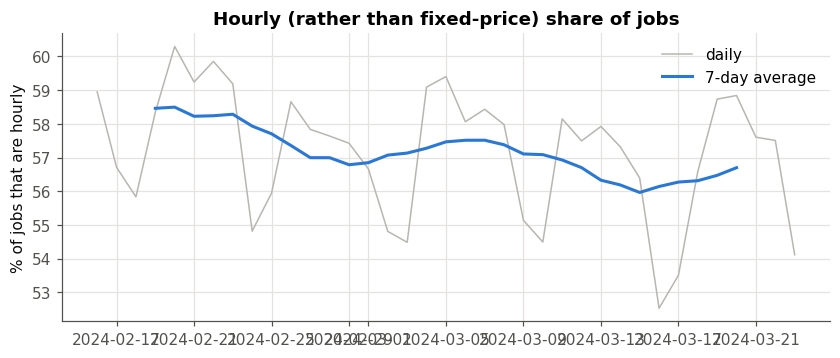

,unit,mean,start,end,change,change_low,change_high,relative_change_pct,p
series,,,,,,,,,
hourly_share,pp,57.187,58.264,56.111,-2.154,-3.179,-1.128,-3.696,0.0


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(remote_daily["date"], 100 * remote_daily["hourly_share"], color=GREY, lw=1, label="daily")
ax.plot(remote_daily["date"], 100 * remote_daily["hourly_share"].rolling(7, center=True).mean(), color=BLUE, lw=2,
        label="7-day average")
ax.set_ylabel("% of jobs that are hourly")
ax.set_title("Hourly (rather than fixed-price) share of jobs")
ax.legend()
plt.show()
series.loc[["hourly_share"]].round(3)

In [16]:
engagement = signals[signals["group"] == "engagement"].pivot(index="signal", columns="iso_week", values="share_pct")
engagement.round(2)

iso_week,2024-W07,2024-W08,2024-W09,2024-W10,2024-W11,2024-W12
signal,,,,,,
full time,0.37,0.37,0.44,0.44,0.44,0.40
long term / ongoing,1.24,0.98,1.07,0.99,1.09,0.98
part time,0.47,0.46,0.47,0.41,0.40,0.44


**Finding.** The **hourly share falls** from about **58.3% to 56.1%** of jobs within the window (about -2.2 pp, interval excluding zero): fixed-price projects gain slightly. Explicit engagement words stay rare and stable: "long term / ongoing" appears in about 1% of titles, "full time" and "part time" in about 0.4% each.

### 2.3 What titles explicitly say about the work arrangement

These are **explicit title mentions**, not the share of jobs that are remote or on-site. Words are matched as whole words: "local seo" does not count as on-site work, and "best" does not count as the time zone "EST". (A small ambiguity remains: "est" is also a French word.)

In [17]:
arrangement = signals[signals["group"] == "work arrangement"]
weekly = arrangement.pivot(index="signal", columns="iso_week", values="title_mentions")
weekly["share of all window titles (%)"] = (100 * arrangement.groupby("signal")["title_mentions"].sum()
                                             / arrangement.groupby("signal")["jobs"].sum()).round(3)
weekly

iso_week,2024-W07,2024-W08,2024-W09,2024-W10,2024-W11,2024-W12,share of all window titles (%)
signal,,,,,,,
hybrid,5,9,14,9,11,9,0.025
on-site / in person / local,10,37,47,36,28,35,0.084
remote,68,237,220,226,216,208,0.512
time-zone requirement,18,44,33,25,28,33,0.079
work from home,4,33,18,15,17,31,0.051


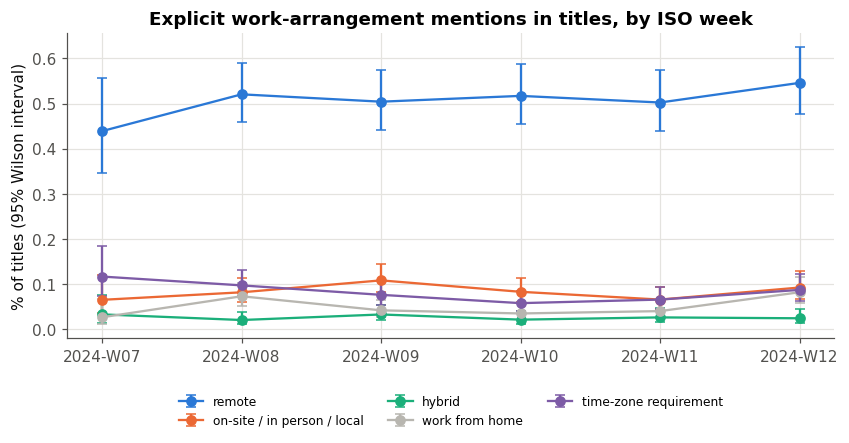

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for color, name in zip([BLUE, ORANGE, AQUA, GREY, "#7d5ba6"], arrangement["signal"].unique()):
    part = arrangement[arrangement["signal"] == name]
    ax.errorbar(part["iso_week"], part["share_pct"], yerr=[part["share_pct"] - part["low_pct"],
                part["high_pct"] - part["share_pct"]], marker="o", capsize=3, color=color, label=name)
ax.set_ylabel("% of titles (95% Wilson interval)")
ax.set_title("Explicit work-arrangement mentions in titles, by ISO week")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()

**Finding.** Explicit arrangement words are **rare and flat**: "remote" appears in about **0.5%** of titles, on-site / in-person / local requirements in under 0.1%, "hybrid" and "work from home" in a handful of titles a week, and time-zone requirements in about 0.1%. The weekly intervals overlap: there is no measurable change. In this market, being remote is the default and rarely needs saying.

### 2.4 Forecasts follow in Notebook 06

Notebook 06 forecasts the Task 7 signals that have enough data: the **hourly share**, the **North American client share** and **geographic concentration**. Rare signals ("remote", "hybrid", on-site mentions, new AI terms) get **no forecast**: their counts are too small for a defensible one.

## 3. Summary

**Task 2 (emerging categories), within 16 Feb - 23 Mar 2024**

- Over the full window, nine functions change significantly: Digital Marketing, Video, Design, Sales, E-commerce and AI & ML gain share; Writing (about -2.0 pp), Admin (-1.4 pp) and Translation (-0.9 pp) lose share.
- Directions hold without reposts, without gap days and in a complete-week comparison; sizes are a range, not a point.
- Part of the change is an early step around 26 February. Gradual change continues afterwards for Writing (down) and for AI & ML, Sales and E-commerce (up).
- Keywords confirm the picture (falling "writers", "data entry", "translation"; rising "crypto", "web3", modern web frameworks).
- *Other / Unclear* is flat, so these are not categorization artefacts.

**Task 7 (online-hiring landscape)**

- Client geography is stable: about 46% North America, concentration equal to about 5 countries.
- Fixed-price work gains slightly against hourly work (-2.2 pp hourly share).
- Explicit remote / on-site / hybrid mentions are rare and flat; the data cannot measure the remote share of jobs.

**Limits:** five weeks only; associations only; unknown collection method; categories inherit Notebook 03's blind accuracy (68.9%).

## 4. Claims check

Every number quoted in this notebook's text, checked against the data:

In [19]:
c = categories.set_index("primary_category")
arr = arrangement.groupby("signal")[["title_mentions", "jobs"]].sum()
arr_share = 100 * arr["title_mentions"] / arr["jobs"]
eng = signals[signals["group"] == "engagement"].groupby("signal")[["title_mentions", "jobs"]].sum()
eng_share = 100 * eng["title_mentions"] / eng["jobs"]
region_mean = regions.groupby("region")["share_pct"].mean()
claims = {
    "37 days": daily["date"].nunique() == 37,
    "Other about 12.5%, flat": (round(other.loc[0, "mean_pct"], 1) == 12.5 and other.loc[0, "change_low_pp"] < 0 < other.loc[0, "change_high_pp"]),
    "writing 5.8% -> 3.7%, -2.0 pp, -35%": (round(c.loc["writing_content", "start_share_pct"], 1) == 5.8
                                         and round(c.loc["writing_content", "end_share_pct"], 1) == 3.7
                                         and round(c.loc["writing_content", "change_pp"], 1) == -2.0
                                         and round(c.loc["writing_content", "relative_change_pct"]) == -35),
    "admin -1.4 pp, -29%": (round(c.loc["admin_virtual_assistance", "change_pp"], 1) == -1.4
                           and round(c.loc["admin_virtual_assistance", "relative_change_pct"]) == -29),
    "translation -0.9 pp, -41%": (round(c.loc["translation_transcription", "change_pp"], 1) == -0.9
                                 and round(c.loc["translation_transcription", "relative_change_pct"]) == -41),
    "marketing +1.0 pp, +10%": (round(c.loc["digital_marketing", "change_pp"], 1) == 1.0
                               and round(c.loc["digital_marketing", "relative_change_pct"]) == 10),
    "video +0.6, design +0.5, sales +0.4 pp": [round(c.loc[k, "change_pp"], 1) for k in
                                               ["video_animation", "design_creative", "sales_lead_generation"]] == [0.6, 0.5, 0.4],
    "AI +19%, +0.25 pp": round(c.loc["ai_ml", "relative_change_pct"]) == 19 and round(c.loc["ai_ml", "change_pp"], 2) == 0.25,
    "e-commerce +9%": round(c.loc["ecommerce_operations", "relative_change_pct"]) == 9,
    "nine significant functions": significant_categories == 9,
    "all significant directions hold": bool(same_sign.all()),
    "writing -35% vs -19% in week comparison": round(c.loc["writing_content", "week_relative_pct"]) == -19,
    "later window: writing -13%, AI +13%, sales +9%, e-commerce +7%": (
        [round(step_check.loc[NAMES[k], "later relative %"]) for k in
         ["writing_content", "ai_ml", "sales_lead_generation", "ecommerce_operations"]] == [-13, 13, 9, 7]
        and all(step_check.loc[NAMES[k], "later trend clear"] == "yes" for k in
                ["writing_content", "ai_ml", "sales_lead_generation", "ecommerce_operations"])),
    "later window: no clear trend for admin, translation, marketing, video, design": all(
        step_check.loc[NAMES[k], "later trend clear"] == "no" for k in
        ["admin_virtual_assistance", "translation_transcription", "digital_marketing", "video_animation", "design_creative"]),
    "crypto about +97%": round(keywords.set_index("keyword").loc["crypto", "relative_change_pct"]) == 97,
    "falling words lose about half": bool((keywords.set_index("keyword").loc[
        ["freelancers", "writers", "data entry", "translation", "writing", "words", "documents"], "relative_change_pct"] < -45).all()),
    "every country has a region": len(unmapped) == 0,
    "missing country about 2%": round(jobs.loc[jobs["eligible_for_timeseries"], "country"].isna().mean() * 100) == 2,
    "North America about 46%": round(series.loc["north_america_share", "mean"]) == 46,
    "Europe about 24%, East Asia about 11%": (round(region_mean["Europe & Central Asia"]) == 24
                                             and round(region_mean["East Asia & Pacific"]) == 11),
    "South Asia 9-11%": bool(regions[regions["region"] == "South Asia"]["share_pct"].between(8.9, 11.5).all()),
    "about 5.2 effective countries": round(series.loc["effective_countries", "mean"], 1) == 5.2,
    "no geography trend": all(series.loc[s, "change_low"] < 0 < series.loc[s, "change_high"]
                              for s in ["north_america_share", "hhi", "effective_countries"]),
    "hourly 58.3% -> 56.1%, -2.2 pp, significant": (round(series.loc["hourly_share", "start"], 1) == 58.3
                                                   and round(series.loc["hourly_share", "end"], 1) == 56.1
                                                   and round(series.loc["hourly_share", "change"], 1) == -2.2
                                                   and series.loc["hourly_share", "change_high"] < 0),
    "long term about 1%, full/part time about 0.4%": (round(eng_share["long term / ongoing"]) == 1
                                                     and all(round(eng_share[s], 1) == 0.4 for s in ["full time", "part time"])),
    "remote about 0.5%": round(arr_share["remote"], 1) == 0.5,
    "on-site under 0.1%, time zone about 0.1%": arr_share["on-site / in person / local"] < 0.1 and round(arr_share["time-zone requirement"], 1) == 0.1,
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
37 days,True
"Other about 12.5%, flat",True
"writing 5.8% -> 3.7%, -2.0 pp, -35%",True
"admin -1.4 pp, -29%",True
"translation -0.9 pp, -41%",True
"marketing +1.0 pp, +10%",True
"video +0.6, design +0.5, sales +0.4 pp",True
"AI +19%, +0.25 pp",True
e-commerce +9%,True
nine significant functions,True
